# 95 How well do the appliance flags predict one another?

Notebook 60 flags nine appliances in every home with rules whose thresholds were set by **injecting** simulated
appliances into real customers' hourly data: AC, electric heating (any, and as the primary heat source), electric
water heater, pool pump, hot tub, EV charging (Level 1 and Level 2) and solar + battery. This notebook asks how much
each flag tells us about the others, and why, starting simple and adding methods that answer what the simpler ones
can't:

1. **Correlation matrix**: the correlation between every pair of flags (phi), and between their confidence scores.
2. **Co-occurrence and lift**: how much more (or less) likely a home is to have appliance B if it has appliance A,
   which, unlike correlation, isn't held down when one appliance is rare.
3. **Conditional associations**: which links remain once all the other appliances are held fixed (direct links)
   and which were carried by a third appliance.
4. **Predictive power**: for each appliance, how well a model using only the *other* flags (logistic regression) or
   their confidence scores (gradient boosting) predicts it, by cross-validated AUC and average precision.
5. **Rule cross-talk, by injection**: add one simulated appliance to 2,000 ordinary homes and record which *other*
   rules start firing. A home can't have bought a hot tub because we simulated an EV charger, so any extra flags are
   the rules confusing one appliance's load for another's.
6. **Real association or rule overlap?** For each pair of appliances that co-occur more than chance, whether
   cross-talk in the rules could explain it.

Inputs: `appliance_inventory` (notebook 60) and the cached hourly arrays. Outputs: result tables in
`onedrive-export/Data/results/` and five charts in `onedrive-export/Data/eda/` (`appliance_flag_correlation.png`,
`appliance_flag_lift.png`, `appliance_flag_conditional_odds.png`, `appliance_flag_prediction.png`,
`appliance_injection_crosstalk.png`).

Run after notebook 60. It takes about a minute.

## Setup

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'  # must be set before importing scikit-learn

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

import avangrid  # noqa: F401
from avangrid import appliances, cache, config, db, grids

PLOT_DIR = config.EDA_DIR

## The nine flags

Each rule in `avangrid.appliances.RULES` gives a confidence score from 0 to 1, and a home is flagged at 0.5 or more
(exactly how `appliance_inventory` stores them). These are the raw rule flags, before notebook 60 combines them into
types (for example, a home flagged for both EV levels counts as Level 2 in `ev_charging_type`).

"Electric heat (primary)" is a stricter version of "Electric heat (any)": every primary-heat home is also flagged for
any electric heat. The two are never used to predict each other below, since that would be trivially accurate.

In [2]:
inv = db.sql('SELECT * FROM appliance_inventory ORDER BY CUSTOMER_NUMBER')
RULE_COLS = {'AC': 'ac_confidence', 'Electric heat (any)': 'elec_heat_confidence',
             'Electric heat (primary)': 'elec_heat_primary_confidence', 'Water heater': 'water_heater_confidence',
             'Pool': 'pool_confidence', 'Hot tub': 'hot_tub_confidence', 'EV Level 1': 'ev_level1_confidence',
             'EV Level 2': 'ev_level2_confidence', 'Solar + battery': 'solar_battery_confidence'}
RULE_OF = {'AC': 'air_conditioning', 'Electric heat (any)': 'electric_heating_any',
           'Electric heat (primary)': 'electric_heating_primary', 'Water heater': 'electric_water_heater',
           'Pool': 'pool', 'Hot tub': 'hot_tub', 'EV Level 1': 'ev_level1', 'EV Level 2': 'ev_level2',
           'Solar + battery': 'solar_battery'}
NAMES = list(RULE_COLS)
NESTED = {'Electric heat (any)': 'Electric heat (primary)', 'Electric heat (primary)': 'Electric heat (any)'}
conf = inv.select(list(RULE_COLS.values())).to_numpy()
flags = conf >= 0.5
N = len(flags)
with pl.Config(tbl_hide_dataframe_shape=True, float_precision=3):
    print(pl.DataFrame({'appliance': NAMES, 'homes_flagged': flags.sum(0), 'share': flags.mean(0)}))

┌─────────────────────────┬───────────────┬───────┐
│ appliance               ┆ homes_flagged ┆ share │
│ ---                     ┆ ---           ┆ ---   │
│ str                     ┆ i64           ┆ f64   │
╞═════════════════════════╪═══════════════╪═══════╡
│ AC                      ┆ 25148         ┆ 0.755 │
│ Electric heat (any)     ┆ 5452          ┆ 0.164 │
│ Electric heat (primary) ┆ 1430          ┆ 0.043 │
│ Water heater            ┆ 4362          ┆ 0.131 │
│ Pool                    ┆ 1187          ┆ 0.036 │
│ Hot tub                 ┆ 1288          ┆ 0.039 │
│ EV Level 1              ┆ 528           ┆ 0.016 │
│ EV Level 2              ┆ 480           ┆ 0.014 │
│ Solar + battery         ┆ 28            ┆ 0.001 │
└─────────────────────────┴───────────────┴───────┘


## 1. Correlation matrix

The simplest summary: the correlation between every pair of flags.

- **Left: phi coefficient**, the ordinary (Pearson) correlation of two yes/no flags. 0 means no association, 1 perfect
  agreement, −1 perfect disagreement.
- **Right: Spearman rank correlation of the confidence scores**, which keeps how close each home came to each
  threshold rather than just yes or no.

One caveat shapes everything after this section: **phi can't get close to 1 when two appliances are very different in
how common they are.** EV Level 2 (1.4% of homes) and AC (75%) could never correlate strongly even if every EV home
had AC. So phi understates associations involving rare appliances, which is why section 2 uses lift instead.

The two electric-heat rows are nested by construction: every primary-heat home is also flagged for any electric
heat (phi 0.48), and both confidence scores rank homes on the same heating evidence (Spearman 1.00). Those two cells
say nothing about appliances, and the two flags are never used to predict each other.

Largest correlations (by |phi|):
┌─────────────────────────┬─────────────────────────┬────────┬─────────────────────┐
│ A                       ┆ B                       ┆ phi    ┆ spearman_confidence │
│ ---                     ┆ ---                     ┆ ---    ┆ ---                 │
│ str                     ┆ str                     ┆ f64    ┆ f64                 │
╞═════════════════════════╪═════════════════════════╪════════╪═════════════════════╡
│ Water heater            ┆ Hot tub                 ┆ 0.329  ┆ 0.425               │
│ Electric heat (any)     ┆ Water heater            ┆ 0.178  ┆ 0.306               │
│ Electric heat (primary) ┆ Water heater            ┆ 0.167  ┆ 0.313               │
│ Hot tub                 ┆ EV Level 2              ┆ 0.164  ┆ 0.432               │
│ Water heater            ┆ EV Level 2              ┆ 0.161  ┆ 0.529               │
│ Electric heat (any)     ┆ Hot tub                 ┆ 0.147  ┆ 0.239               │
│ Water heater            ┆ Pool

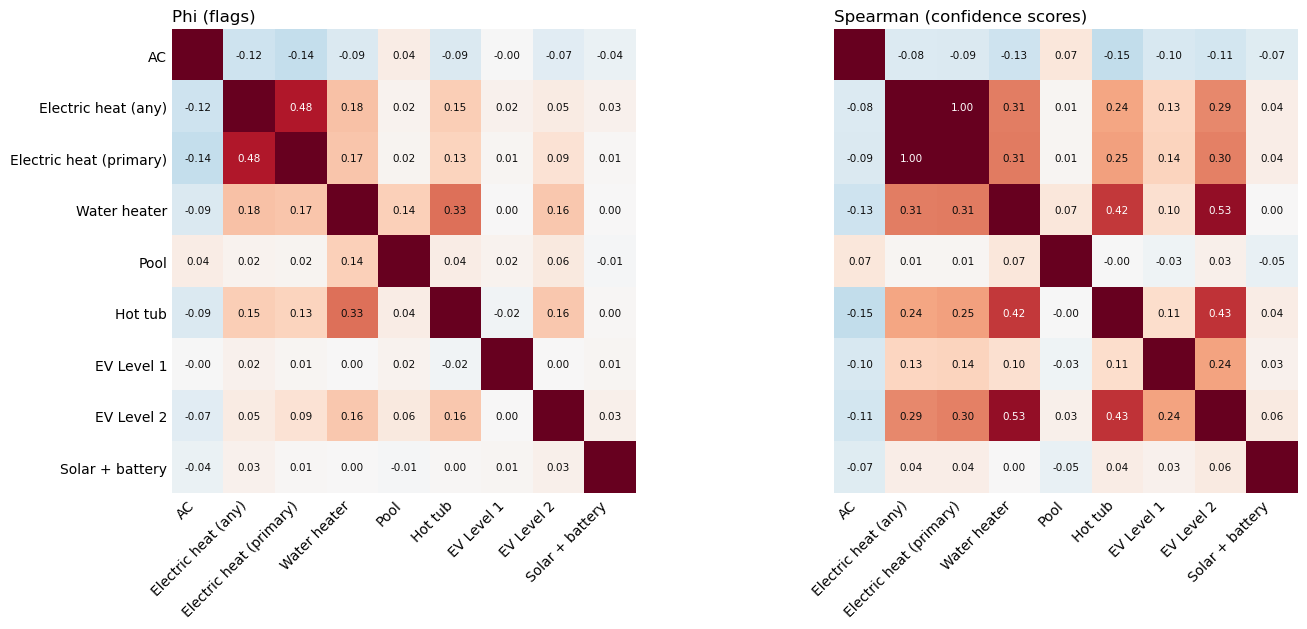

In [3]:
from scipy.stats import spearmanr

phi = np.corrcoef(flags.T.astype(float))
rho = spearmanr(conf).statistic
corr_pairs = pl.DataFrame([{'A': NAMES[i], 'B': NAMES[j], 'phi': phi[i, j], 'spearman_confidence': rho[i, j]}
                           for i in range(len(NAMES)) for j in range(i + 1, len(NAMES))
                           if NAMES[j] != NESTED.get(NAMES[i])])
cache.save_results('appliance_flag_correlation', corr_pairs)
with pl.Config(tbl_rows=12, tbl_hide_dataframe_shape=True, float_precision=3, tbl_width_chars=160):
    print('Largest correlations (by |phi|):')
    print(corr_pairs.sort(pl.col('phi').abs(), descending=True).head(10))

fig, axes = plt.subplots(1, 2, figsize=(15, 6.4))
for ax, R, title in [(axes[0], phi, 'Phi (flags)'), (axes[1], rho, 'Spearman (confidence scores)')]:
    ax.imshow(R, cmap='RdBu_r', vmin=-0.6, vmax=0.6)
    for (i, j), v in np.ndenumerate(R):
        if i != j:
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7.5,
                    color='white' if abs(v) > 0.4 else '#0b0b0b')
    ax.set_xticks(range(len(NAMES)), NAMES, rotation=45, ha='right')
    ax.set_yticks(range(len(NAMES)), NAMES if ax is axes[0] else [''] * len(NAMES))
    ax.set_title(title, loc='left')
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)
fig.tight_layout()
fig.savefig(PLOT_DIR / 'appliance_flag_correlation.png', dpi=150)
plt.show()

## 2. Co-occurrence and lift

For each pair: the share of homes with A that also have B, and the **lift**, that share divided by B's share among all
homes. Lift 1 means A tells you nothing about B; 2 means homes with A are twice as likely to have B; 0.5 half as
likely. In the chart, lift is on a log scale (red above 1, blue below), and pairs with fewer than 20 homes having both
are left grey, since their lift is too uncertain to read.

Strongest associations (at least 20 homes with both):
┌─────────────────────────┬─────────────────────────┬─────────────────┬───────────────────┬─────────────────────┬───────┐
│ A                       ┆ B                       ┆ homes_with_both ┆ share_of_A_with_B ┆ share_of_all_with_B ┆ lift  │
│ ---                     ┆ ---                     ┆ ---             ┆ ---               ┆ ---                 ┆ ---   │
│ str                     ┆ str                     ┆ i64             ┆ f64               ┆ f64                 ┆ f64   │
╞═════════════════════════╪═════════════════════════╪═════════════════╪═══════════════════╪═════════════════════╪═══════╡
│ Hot tub                 ┆ EV Level 2              ┆ 144             ┆ 0.112             ┆ 0.014               ┆ 7.759 │
│ EV Level 2              ┆ Hot tub                 ┆ 144             ┆ 0.300             ┆ 0.039               ┆ 7.759 │
│ Water heater            ┆ Hot tub                 ┆ 881             ┆ 0.202             ┆ 

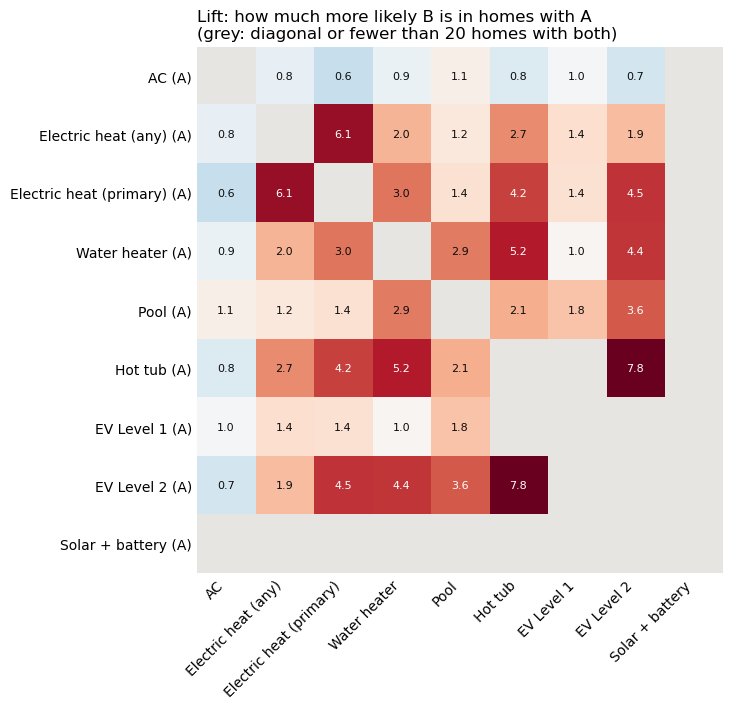

In [4]:
MIN_BOTH = 20
k = len(NAMES)
both = flags.T.astype(int) @ flags.astype(int)                         # homes with A and B
p_b = flags.mean(0)
cond = both / np.maximum(flags.sum(0), 1)[:, None]                      # row A, column B: P(B | A)
lift = cond / p_b[None, :]
pairs = pl.DataFrame([{'A': NAMES[i], 'B': NAMES[j], 'homes_with_both': int(both[i, j]),
                       'share_of_A_with_B': cond[i, j], 'share_of_all_with_B': p_b[j], 'lift': lift[i, j]}
                      for i in range(k) for j in range(k) if i != j and NAMES[j] != NESTED.get(NAMES[i])])
cache.save_results('appliance_flag_cooccurrence', pairs)
with pl.Config(tbl_rows=20, tbl_hide_dataframe_shape=True, float_precision=3, tbl_width_chars=160):
    print('Strongest associations (at least 20 homes with both):')
    print(pairs.filter(pl.col('homes_with_both') >= MIN_BOTH).sort('lift', descending=True).head(12))
    print('Weakest (A makes B less likely):')
    print(pairs.filter(pl.col('homes_with_both') >= MIN_BOTH).sort('lift').head(6))

L = np.log2(np.where(both >= MIN_BOTH, lift, np.nan))
np.fill_diagonal(L, np.nan)
fig, ax = plt.subplots(figsize=(9, 7.2))
ax.set_facecolor('#e6e5e1')
ax.imshow(L, cmap='RdBu_r', vmin=-3, vmax=3)
for i in range(k):
    for j in range(k):
        if i != j and both[i, j] >= MIN_BOTH:
            ax.text(j, i, f'{lift[i, j]:.1f}', ha='center', va='center', fontsize=8,
                    color='white' if abs(L[i, j]) > 1.8 else '#0b0b0b')
ax.set_xticks(range(k), NAMES, rotation=45, ha='right')
ax.set_yticks(range(k), [f'{n} (A)' for n in NAMES])
ax.set_title('Lift: how much more likely B is in homes with A\n(grey: diagonal or fewer than 20 homes with both)', loc='left')
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
fig.tight_layout()
fig.savefig(PLOT_DIR / 'appliance_flag_lift.png', dpi=150)
plt.show()

## 3. Conditional associations: which links are direct?

Two appliances can co-occur only because both go with a third. To separate direct from indirect links, each flag is
regressed on **all the other flags at once** (logistic regression; the two electric-heat flags are never used for
each other). The **odds ratio** for B in the model for A is how much more likely A is when B is present, *holding
every other appliance fixed*. 95% confidence intervals come from the model's standard errors; cells whose interval
includes 1 (no effect) are left grey.

Compared with the lift in section 2, a link that stays strong here is direct; one that shrinks towards 1 was mostly
carried by other appliances.

Links whose 95% interval excludes 1, strongest first (each pair once, A modelled on B):


┌─────────────────────────┬─────────────────────────┬────────────┬────────┬─────────┬───────────────┐
│ A (modelled)            ┆ B (predictor)           ┆ odds_ratio ┆ ci_low ┆ ci_high ┆ marginal_lift │
│ ---                     ┆ ---                     ┆ ---        ┆ ---    ┆ ---     ┆ ---           │
│ str                     ┆ str                     ┆ f64        ┆ f64    ┆ f64     ┆ f64           │
╞═════════════════════════╪═════════════════════════╪════════════╪════════╪═════════╪═══════════════╡
│ Hot tub                 ┆ Water heater            ┆ 13.16      ┆ 11.56  ┆ 14.98   ┆ 5.22          │
│ AC                      ┆ Solar + battery         ┆ 0.09       ┆ 0.03   ┆ 0.24    ┆ 0.24          │
│ EV Level 1              ┆ Hot tub                 ┆ 0.18       ┆ 0.07   ┆ 0.45    ┆ 0.24          │
│ EV Level 2              ┆ Water heater            ┆ 5.17       ┆ 4.17   ┆ 6.42    ┆ 4.44          │
│ Pool                    ┆ Water heater            ┆ 4.63       ┆ 4.05   ┆ 5.29  

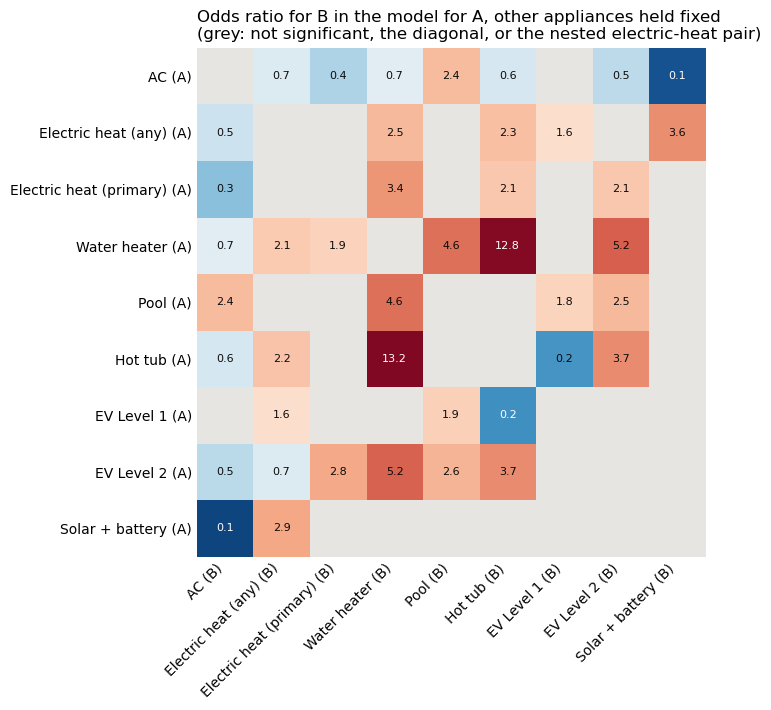

In [5]:
def logit_odds_ratios(X, y):
    """Unpenalized logistic regression; odds ratios and 95% CIs from the inverse Fisher information."""
    m = LogisticRegression(penalty=None, max_iter=5000).fit(X, y)
    Xd = np.column_stack([np.ones(len(X)), X])
    p = m.predict_proba(X)[:, 1]
    cov = np.linalg.pinv(Xd.T @ (Xd * (p * (1 - p))[:, None]))
    beta, se = m.coef_[0], np.sqrt(np.diag(cov))[1:]
    return np.exp(beta), np.exp(beta - 1.96 * se), np.exp(beta + 1.96 * se)


OR, OR_lo, OR_hi = (np.full((k, k), np.nan) for _ in range(3))
for t, name in enumerate(NAMES):
    others = [j for j, other in enumerate(NAMES) if j != t and other != NESTED.get(name)]
    o, lo, hi = logit_odds_ratios(flags[:, others].astype(float), flags[:, t])
    OR[t, others], OR_lo[t, others], OR_hi[t, others] = o, lo, hi
cond_pairs = pl.DataFrame([{'A (modelled)': NAMES[i], 'B (predictor)': NAMES[j], 'odds_ratio': OR[i, j],
                            'ci_low': OR_lo[i, j], 'ci_high': OR_hi[i, j], 'marginal_lift': lift[i, j]}
                           for i in range(k) for j in range(k) if not np.isnan(OR[i, j])])
cache.save_results('appliance_flag_conditional_odds', cond_pairs)
sig = (OR_lo > 1) | (OR_hi < 1)
with pl.Config(tbl_rows=-1, tbl_hide_dataframe_shape=True, float_precision=2, tbl_width_chars=180):
    print('Links whose 95% interval excludes 1, strongest first (each pair once, A modelled on B):')
    print(cond_pairs.filter((pl.col('ci_low') > 1) | (pl.col('ci_high') < 1))
          .filter(pl.col('A (modelled)') < pl.col('B (predictor)'))
          .sort(pl.col('odds_ratio').log().abs(), descending=True))

LO = np.where(sig, np.log2(OR), np.nan)
fig, ax = plt.subplots(figsize=(9, 7.2))
ax.set_facecolor('#e6e5e1')
ax.imshow(LO, cmap='RdBu_r', vmin=-4, vmax=4)
for (i, j), v in np.ndenumerate(OR):
    if sig[i, j]:
        ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=8,
                color='white' if abs(LO[i, j]) > 2.4 else '#0b0b0b')
ax.set_xticks(range(k), [f'{n} (B)' for n in NAMES], rotation=45, ha='right')
ax.set_yticks(range(k), [f'{n} (A)' for n in NAMES])
ax.set_title('Odds ratio for B in the model for A, other appliances held fixed\n'
             '(grey: not significant, the diagonal, or the nested electric-heat pair)', loc='left')
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
fig.tight_layout()
fig.savefig(PLOT_DIR / 'appliance_flag_conditional_odds.png', dpi=150)
plt.show()

## 4. How well the other flags predict each one

For each appliance, two cross-validated models (5 stratified folds) predict it from the **other** appliances only:

- **Other flags**: logistic regression on the eight other yes/no flags (seven for the two electric-heat flags).
- **Other confidence scores**: gradient boosting on the other rules' 0–1 confidence scores, which keep how close a home
  came to each threshold and can pick up interactions.

**AUC** is the chance that a randomly chosen home with the appliance scores above one without it (0.5 = no
information). **Average precision** summarises how pure the top of the ranking is; it is compared with the
appliance's prevalence, which is what random ranking would give (`ap_vs_random`). The strongest predictor is the
other flag with the largest logistic-regression odds ratio, fitted on all homes.

┌─────────────────────────┬───────┬─────────────────────────┬───────┬───────────────────┬──────────────┬──────────────────────────────────────┐
│ appliance               ┆ homes ┆ inputs                  ┆ auc   ┆ average_precision ┆ ap_vs_random ┆ strongest_predictor                  │
│ ---                     ┆ ---   ┆ ---                     ┆ ---   ┆ ---               ┆ ---          ┆ ---                                  │
│ str                     ┆ i64   ┆ str                     ┆ f64   ┆ f64               ┆ f64          ┆ str                                  │
╞═════════════════════════╪═══════╪═════════════════════════╪═══════╪═══════════════════╪══════════════╪══════════════════════════════════════╡
│ AC                      ┆ 25148 ┆ other flags             ┆ 0.584 ┆ 0.794             ┆ 1.052        ┆ Pool (odds ratio 2.4)                │
│ AC                      ┆ 25148 ┆ other confidence scores ┆ 0.681 ┆ 0.852             ┆ 1.128        ┆ Pool (odds ratio 2.4)          

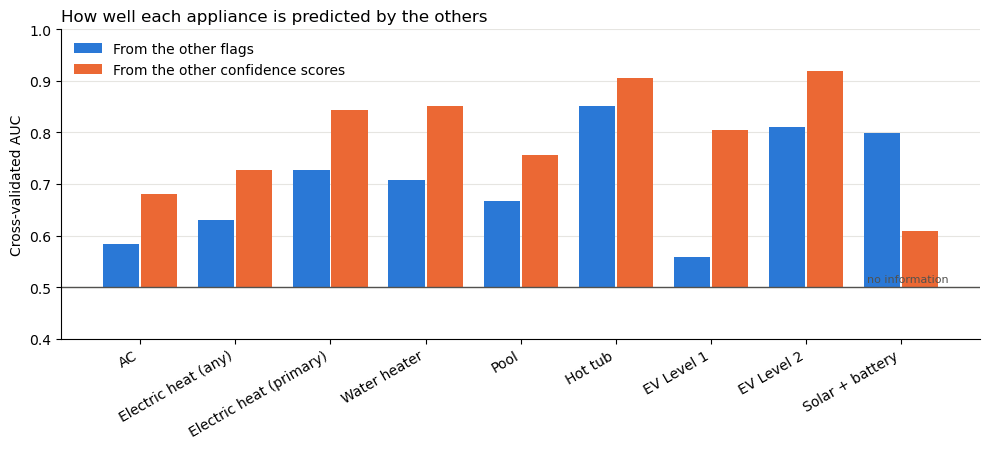

In [6]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)
rows = []
for t, name in enumerate(NAMES):
    y = flags[:, t]
    others = [j for j, other in enumerate(NAMES) if j != t and other != NESTED.get(name)]
    full = LogisticRegression(max_iter=2000).fit(flags[:, others].astype(float), y)
    odds = np.exp(full.coef_[0])
    best = int(np.argmax(odds))
    for inputs, X, model in [('other flags', flags[:, others].astype(float), LogisticRegression(max_iter=2000)),
                             ('other confidence scores', conf[:, others],
                              HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=0))]:
        p = cross_val_predict(model, X, y, cv=cv, method='predict_proba')[:, 1]
        ap = average_precision_score(y, p)
        rows.append({'appliance': name, 'homes': int(y.sum()), 'inputs': inputs, 'auc': roc_auc_score(y, p),
                     'average_precision': ap, 'ap_vs_random': ap / y.mean(),
                     'strongest_predictor': f'{NAMES[others[best]]} (odds ratio {odds[best]:.1f})'})
pred = pl.DataFrame(rows)
cache.save_results('appliance_flag_prediction', pred)
with pl.Config(tbl_rows=-1, tbl_hide_dataframe_shape=True, float_precision=3, tbl_width_chars=200, fmt_str_lengths=50):
    print(pred)

fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(NAMES))
for off, (inputs, color) in zip((-0.2, 0.2), [('other flags', '#2a78d6'), ('other confidence scores', '#eb6834')]):
    a = pred.filter(pl.col('inputs') == inputs)['auc'].to_numpy()
    ax.bar(x + off, a - 0.5, bottom=0.5, width=0.38, color=color, label=f'From the {inputs}')
ax.axhline(0.5, color='#52514e', linewidth=1)
ax.text(len(NAMES) - 0.5, 0.505, 'no information', ha='right', va='bottom', fontsize=8, color='#52514e')
ax.set_xticks(x, NAMES, rotation=30, ha='right')
ax.set_ylim(0.4, 1)
ax.set_ylabel('Cross-validated AUC')
ax.set_title('How well each appliance is predicted by the others', loc='left')
ax.legend(frameon=False, loc='upper left')
ax.grid(axis='y', color='#e6e5e1')
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(PLOT_DIR / 'appliance_flag_prediction.png', dpi=150)
plt.show()

## 5. Rule cross-talk, by injection

The same set-up as notebook 60's calibration: 2,000 random homes on none of the EV/HP/PV lists, each given one kind of
simulated appliance (`appliances.inject`), with the features recomputed and every rule re-applied using the
population's scales. Solar + battery is tested on the PV-list homes with a simulated battery added, since the rule
only applies to solar homes.

Each cell is the share of homes **not** flagged for that rule before the injection that **are** flagged after it. The
diagonal (the rule meant for the injected appliance) is the rule's sensitivity; everything off the diagonal is
cross-talk: a rule mistaking one appliance's load for another's.

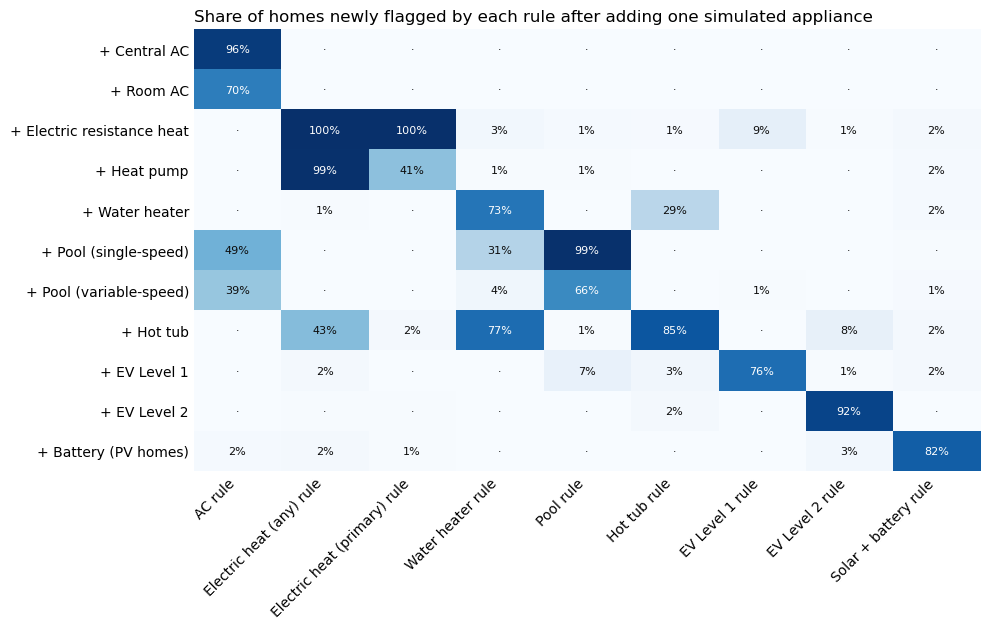

Cross-talk of 2% or more (a rule firing for an appliance it is not meant for):
┌──────────────────────────┬─────────────────────────┬───────────────┐
│ injected                 ┆ rule                    ┆ newly_flagged │
│ ---                      ┆ ---                     ┆ ---           │
│ str                      ┆ str                     ┆ f64           │
╞══════════════════════════╪═════════════════════════╪═══════════════╡
│ Hot tub                  ┆ Water heater            ┆ 0.768         │
│ Pool (single-speed)      ┆ AC                      ┆ 0.485         │
│ Hot tub                  ┆ Electric heat (any)     ┆ 0.434         │
│ Pool (variable-speed)    ┆ AC                      ┆ 0.394         │
│ Pool (single-speed)      ┆ Water heater            ┆ 0.307         │
│ Water heater             ┆ Hot tub                 ┆ 0.286         │
│ Electric resistance heat ┆ EV Level 1              ┆ 0.090         │
│ Hot tub                  ┆ EV Level 2              ┆ 0.082         

In [7]:
hd = grids.load_hourly(verbose=False)
lab = hd.labels()
not_listed = np.flatnonzero(~(lab['EV'] | lab['HP'] | lab['PV']))
sample = np.sort(np.random.default_rng(42).choice(not_listed, 2000, replace=False))
F_all = appliances.appliance_features(hd.kwh, hd.temp_hourly, hd.dates, hd.weekend)
scales = appliances.fit_scales(F_all)


def rule_flags(F):
    c = appliances.classify(F, scales)
    return np.column_stack([c[RULE_OF[n]] >= 0.5 for n in NAMES])


INJECTED = {'Central AC': 'air_conditioning', 'Room AC': 'room_air_conditioning',
            'Electric resistance heat': 'electric_heating', 'Heat pump': 'heat_pump_heating',
            'Water heater': 'electric_water_heater', 'Pool (single-speed)': 'pool',
            'Pool (variable-speed)': 'pool_variable_speed', 'Hot tub': 'hot_tub', 'EV Level 1': 'ev_level1',
            'EV Level 2': 'ev_level2', 'Battery (PV homes)': 'battery'}
rows, M = [], []
for label, kind in INJECTED.items():
    idx = np.flatnonzero(lab['PV']) if kind == 'battery' else sample
    before = rule_flags({f: v[idx] for f, v in F_all.items()})
    K_inj = appliances.inject(np.asarray(hd.kwh[idx]), kind, hd.temp_hourly, hd.dates, np.random.default_rng(7))
    after = rule_flags(appliances.appliance_features(K_inj, hd.temp_hourly, hd.dates, hd.weekend))
    newly = (after & ~before).sum(0) / np.maximum((~before).sum(0), 1)
    M.append(newly)
    rows += [{'injected': label, 'rule': n, 'newly_flagged': float(newly[j])} for j, n in enumerate(NAMES)]
M = np.array(M)
crosstalk = pl.DataFrame(rows)
cache.save_results('appliance_injection_crosstalk', crosstalk)

fig, ax = plt.subplots(figsize=(10, 6.4))
ax.imshow(M, cmap='Blues', vmin=0, vmax=1, aspect='auto')
for (i, j), v in np.ndenumerate(M):
    ax.text(j, i, f'{v:.0%}' if v >= 0.005 else '·', ha='center', va='center', fontsize=8,
            color='white' if v > 0.55 else '#0b0b0b')
ax.set_xticks(range(len(NAMES)), [f'{n} rule' for n in NAMES], rotation=45, ha='right')
ax.set_yticks(range(len(INJECTED)), [f'+ {lbl}' for lbl in INJECTED])
ax.set_title('Share of homes newly flagged by each rule after adding one simulated appliance', loc='left')
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
fig.tight_layout()
fig.savefig(PLOT_DIR / 'appliance_injection_crosstalk.png', dpi=150)
plt.show()

off = crosstalk.join(pl.DataFrame({'injected': list(INJECTED), 'own_rule': ['AC', 'AC', 'Electric heat (any)',
                     'Electric heat (any)', 'Water heater', 'Pool', 'Pool', 'Hot tub', 'EV Level 1', 'EV Level 2',
                     'Solar + battery']}), on='injected')
own_family = {'Electric heat (any)': {'Electric heat (any)', 'Electric heat (primary)'}}
off = off.filter(~pl.struct('rule', 'own_rule').map_elements(
    lambda r: r['rule'] in own_family.get(r['own_rule'], {r['own_rule']}), return_dtype=pl.Boolean))
with pl.Config(tbl_rows=-1, tbl_hide_dataframe_shape=True, float_precision=3):
    print('Cross-talk of 2% or more (a rule firing for an appliance it is not meant for):')
    print(off.filter(pl.col('newly_flagged') >= 0.02).sort('newly_flagged', descending=True).drop('own_rule'))

## 6. Real association, or rule overlap?

For every pair of appliances that co-occur at least 1.5 times as often as chance (section 2), the cross-talk between
their rules in both directions (section 5: injecting A and watching B's rule, and the reverse). If adding one
appliance trips the other's rule in 5% or more of homes, part of the association could be the rules confusing the two
loads rather than homes really owning both.

In [8]:
INJECT_FOR = {'AC': 'Central AC', 'Electric heat (any)': 'Electric resistance heat',
              'Electric heat (primary)': 'Electric resistance heat', 'Water heater': 'Water heater',
              'Pool': 'Pool (single-speed)', 'Hot tub': 'Hot tub', 'EV Level 1': 'EV Level 1',
              'EV Level 2': 'EV Level 2', 'Solar + battery': 'Battery (PV homes)'}
inj_row = {lbl: i for i, lbl in enumerate(INJECTED)}
syn = []
for i in range(k):
    for j in range(i + 1, k):
        if NAMES[j] == NESTED.get(NAMES[i]) or both[i, j] < MIN_BOTH or lift[i, j] < 1.5:
            continue
        a_to_b = M[inj_row[INJECT_FOR[NAMES[i]]], j]
        b_to_a = M[inj_row[INJECT_FOR[NAMES[j]]], i]
        syn.append({'A': NAMES[i], 'B': NAMES[j], 'homes_with_both': int(both[i, j]), 'lift': lift[i, j],
                    'adding_A_flags_B': a_to_b, 'adding_B_flags_A': b_to_a,
                    'reading': 'rule overlap could explain part of it' if max(a_to_b, b_to_a) >= 0.05
                               else 'not rule overlap: homes really have both, or share a trait'})
syn = pl.DataFrame(syn).sort('lift', descending=True)
cache.save_results('appliance_flag_association_vs_crosstalk', syn)
with pl.Config(tbl_rows=-1, tbl_hide_dataframe_shape=True, float_precision=3, tbl_width_chars=200, fmt_str_lengths=60):
    print(syn)

┌─────────────────────────┬──────────────┬─────────────────┬───────┬──────────────────┬──────────────────┬────────────────────────────────────────────────────────────┐
│ A                       ┆ B            ┆ homes_with_both ┆ lift  ┆ adding_A_flags_B ┆ adding_B_flags_A ┆ reading                                                    │
│ ---                     ┆ ---          ┆ ---             ┆ ---   ┆ ---              ┆ ---              ┆ ---                                                        │
│ str                     ┆ str          ┆ i64             ┆ f64   ┆ f64              ┆ f64              ┆ str                                                        │
╞═════════════════════════╪══════════════╪═════════════════╪═══════╪══════════════════╪══════════════════╪════════════════════════════════════════════════════════════╡
│ Hot tub                 ┆ EV Level 2   ┆ 144             ┆ 7.759 ┆ 0.082            ┆ 0.019            ┆ rule overlap could explain part of it                

## What this shows

*Figures from the 13 Nov 2026 run (33,310 customers); the tables above update on a re-run, this text doesn't.*

**Correlation alone says the flags are only weakly related.** No pair of flags has a phi coefficient above 0.33
(water heater with hot tub); most are under 0.15. But phi is held down whenever one appliance is rare: hot tub and EV
Level 2 correlate at only 0.16, yet homes with one are 7.8 times as likely to have the other. The confidence scores
correlate more strongly than the flags (Spearman up to 0.53, for EV Level 2 with water heater), because they also
capture homes that came close to a threshold without crossing it.

**Lift shows the flags are far from independent.** Several pairs co-occur 2–8 times as often as chance. Homes with EV Level 2
charging are 7.8 times as likely as average to be flagged for a hot tub, and 68% of hot-tub homes are also flagged
for an electric water heater (5.2 times the 13% overall). AC is the one flag that tells you little in either direction:
three-quarters of homes have it.

**Some of those links are indirect.** Holding all the other appliances fixed (section 3):

- **Hot tub–EV Level 2** falls from a lift of 7.8 to an odds ratio of 3.7. Both go with electric water heating, which
  carries much of the link.
- **EV Level 2–water heater** stays strong (odds ratio 5.2, lift 4.4), as do **hot tub–water heater** (13.2) and
  **pool–water heater** (4.6). These are the direct links.
- **EV Level 2 and electric heating**: the link is with *primary* electric heat (2.9). With primary heat held fixed,
  homes with only supplementary electric heat are slightly *less* likely to charge an EV (0.68).
- **AC–pool** goes the other way: almost no link on its own (lift 1.1), but a clear one once other appliances are held
  fixed (2.4). Section 5 shows why: a pool pump trips the AC rule.

**Predictive power varies widely.** From the other eight flags alone, cross-validated AUC ranges from 0.56 (EV Level 1)
and 0.58 (AC), little better than chance, to 0.81 (EV Level 2) and 0.85 (hot tub). Using the other rules' confidence
scores instead of their yes/no flags adds information for every appliance (AUC 0.61–0.92), most for EV Level 1 (0.56
→ 0.80) and EV Level 2 (0.81 → 0.92). Solar + battery has only 28 homes, too few to read.

**But much of that predictive power is the rules overlapping, not homes owning both.** Injection shows which rules
mistake one load for another:

- **Water heater and hot tub confuse each other.** Adding a simulated hot tub trips the water-heater rule in 77% of
  homes, and adding a water heater trips the hot-tub rule in 29%. Both look for short spikes above a quiet base, at
  different times of day, and a hot tub's heater cycles at all hours. Their strong association (and the odds ratio of
  13 between them) is mostly this overlap.
- **Pool pumps trip the AC rule** (49% of homes, 39% for variable-speed pumps) and the water-heater rule (31%): a pump
  runs on warm summer days, which the AC rule reads as cooling load. Part of the AC–pool association is therefore the
  rule, not the home.
- **Hot tubs trip the electric-heating rule** (43%): a tub's heater works harder in cold weather, like electric heat.
- **Smaller overlaps**: hot tub → EV Level 2 (8%), electric resistance heat → EV Level 1 (9%), EV Level 1 → pool (7%).

**Associations the rules can't explain.** EV Level 2 co-occurs with primary electric heat (4.5×), electric water heat
(4.4×), pools (3.6×) and any electric heat (1.9×), with no cross-talk in either direction. These may be real: larger,
more electrified homes own more of these loads. They may also be loads the injections don't simulate. The simulated
water heater draws in the morning and evening, but a water heater or storage heater on an **overnight timer** would
look like EV charging to the night-time Level 2 rule.

**Implications** (not yet applied anywhere else):

- Co-occurring flags shouldn't be counted as independent evidence. Notebook 70's `flexible_load` segment counts
  homes with 2+ controllable loads among central AC, EV charging, water heater, pool and hot tub; the hot-tub/water-
  heater overlap alone will push some homes over that bar with only one real appliance.
- The hot-tub and water-heater rules need a feature that separates them (for example, spikes concentrated in the
  morning for water heaters versus all-hours cycling that rises in cold weather for hot tubs) before either flag is
  used on its own.
- The thresholds in `avangrid.appliances.RULES` are the ones chosen by an earlier calibration on fewer customers;
  notebook 60's latest calibration picked slightly different ones (for example EV Level 2 at 0.20 rather than 0.25),
  and these results use the thresholds in `RULES`.

## Tried but not used

| Tried | Why it isn't used |
|---|---|
| **Predicting each appliance from the rules' underlying evidence features** (for example night-time spike shares) rather than from the other flags and confidence scores | Considered, not run. Several rules are computed from the same inputs (the hot-tub and both EV rules all read the same mild nights), so a model on those features would partly measure shared inputs rather than whether one appliance predicts another. |
| **Reading results for solar + battery** | Only 28 homes are flagged, so its AUCs (0.80 from flags, 0.61 from scores) swing with a handful of homes; it's kept in the tables for completeness but not interpreted. |